# Imports

In [1]:
from CanterraFunctions import combustionProps
import numpy as np
import matplotlib.pyplot as plt
import cantera as ct

### Matplotlib theme

In [2]:
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.colormaps['tab10'].colors)

### Setup

In [3]:
sp = [s for s in ct.Species.list_from_file("nDodecane_Reitz.yaml")
      if set(s.composition) <= {"C", "H", "O"}]
GAS = ct.Solution(thermo="ideal-gas", species=sp)
GRAPHITE = ct.Solution("graphite.yaml")

MRRange = np.linspace(0.05, 4, 100)
chamberPs = [50, 100, 150]

# Baseline Equilibrium Properties

In [4]:
Ts     = np.zeros((len(chamberPs), len(MRRange)))
gammas = np.zeros_like(Ts)
Cps    = np.zeros_like(Ts)

for i, Pcc in enumerate(chamberPs):
    for j, MR in enumerate(MRRange):
        props = combustionProps(MR=MR, Pcc=Pcc, gas=GAS)
        Ts[i, j]     = props.T
        gammas[i, j] = props.gamma
        Cps[i, j]    = props.cp


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3001.513323813797 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3017.9656455602667 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


### Plots

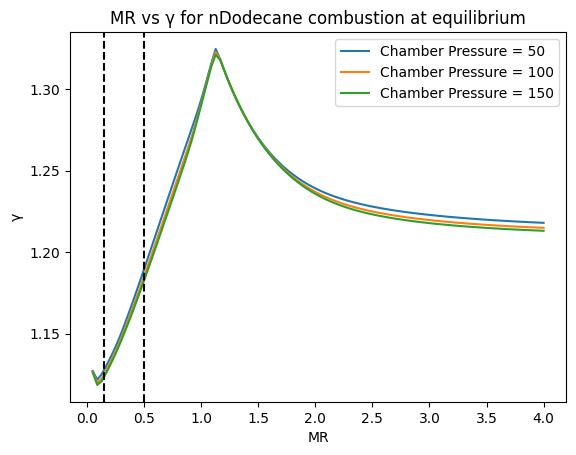

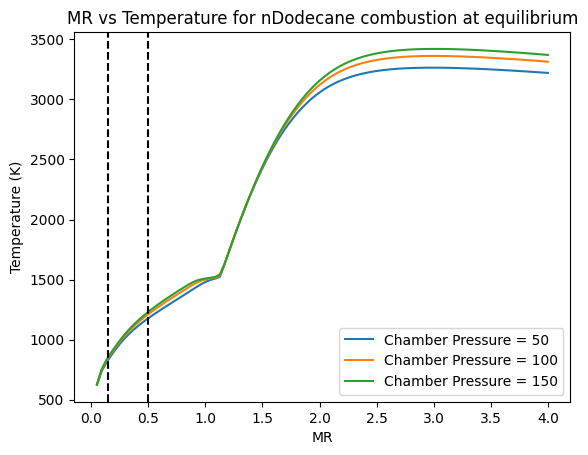

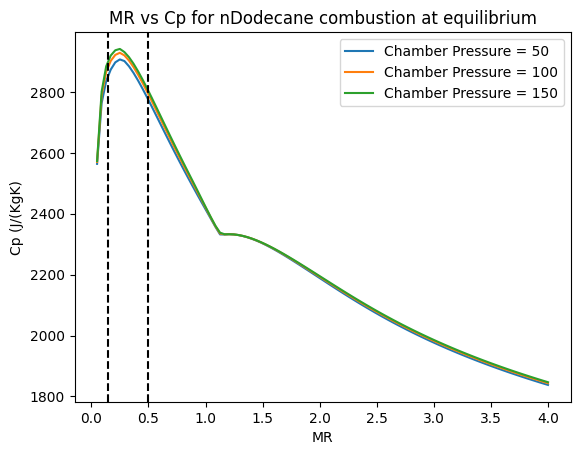

In [5]:
# Gamma plot
for i in range(len(chamberPs)):
    plt.plot(MRRange, gammas[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs \u03b3 for nDodecane combustion at equilibrium")
plt.xlabel("MR")
plt.ylabel("\u03b3")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Temp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, Ts[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Temperature for nDodecane combustion at equilibrium")
plt.xlabel("MR")
plt.ylabel("Temperature (K)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

# Cp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, Cps[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Cp for nDodecane combustion at equilibrium")
plt.xlabel("MR")
plt.ylabel("Cp (J/(KgK)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Soot Modelled Properties 

In [6]:
sootTs     = np.zeros((len(chamberPs), len(MRRange)))
sootgammas = np.zeros_like(sootTs)
sootCps    = np.zeros_like(sootTs)

for i, Pcc in enumerate(chamberPs):
    for j, MR in enumerate(MRRange):
        props = combustionProps(MR=MR, Pcc=Pcc, soot=True, gas=GAS, graphite=GRAPHITE)
        sootTs[i, j]     = props.T
        sootgammas[i, j] = props.gamma
        sootCps[i, j]    = props.cp

### Plots

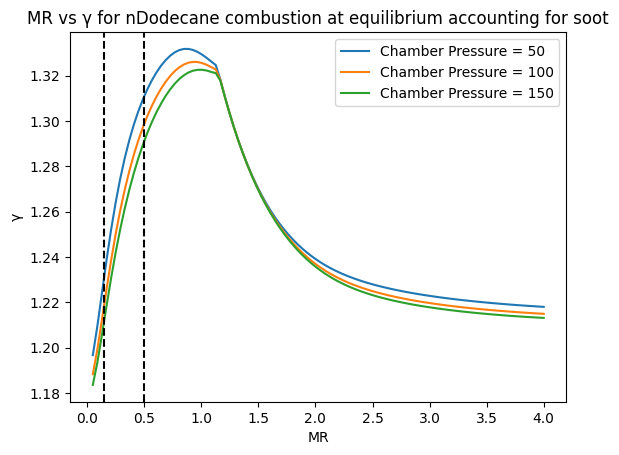

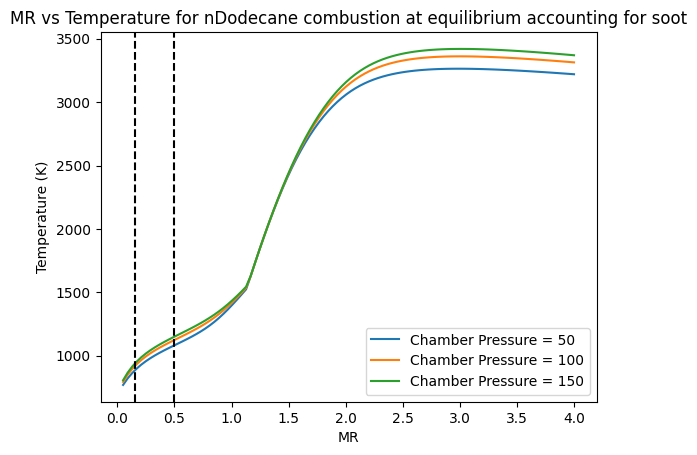

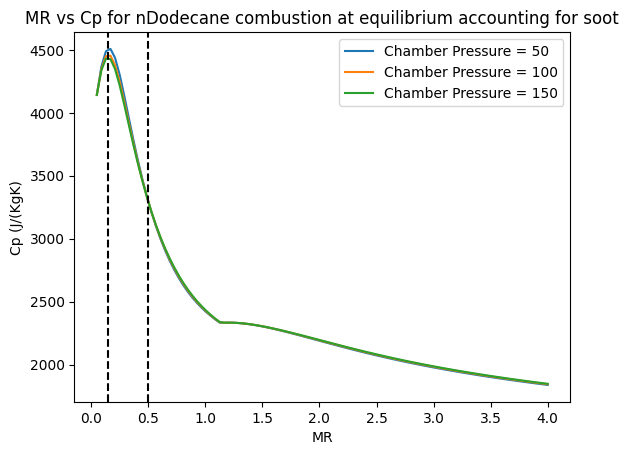

In [7]:
# Gamma plot
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootgammas[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs \u03b3 for nDodecane combustion at equilibrium accounting for soot")
plt.xlabel("MR")
plt.ylabel("\u03b3")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Temp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootTs[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Temperature for nDodecane combustion at equilibrium accounting for soot")
plt.xlabel("MR")
plt.ylabel("Temperature (K)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

# Cp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootCps[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Cp for nDodecane combustion at equilibrium accounting for soot")
plt.xlabel("MR")
plt.ylabel("Cp (J/(KgK)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Comparison

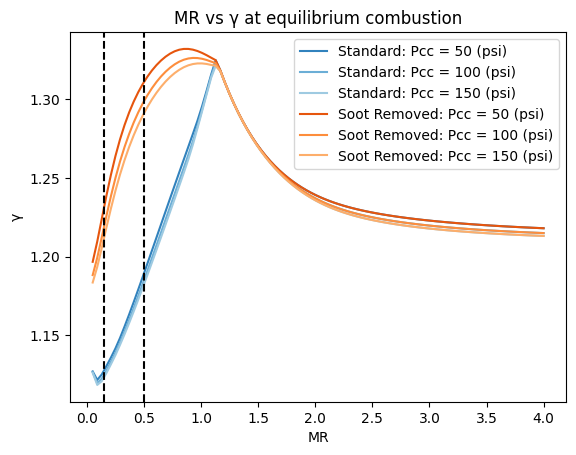

In [8]:
# gamma comparison
colors = plt.get_cmap('tab20c').colors   # tuple of 20 RGB colors
colors = plt.get_cmap('tab20c').colors
for i in range(len(chamberPs)):
    plt.plot(MRRange, gammas[i, :], label=f"Standard: Pcc = {chamberPs[i]} (psi)", color=colors[i])
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootgammas[i, :],     label=f"Soot Removed: Pcc = {chamberPs[i]} (psi)",     color=colors[i + 4])
plt.title("MR vs \u03b3 at equilibrium combustion")
plt.xlabel("MR")
plt.ylabel("\u03b3")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

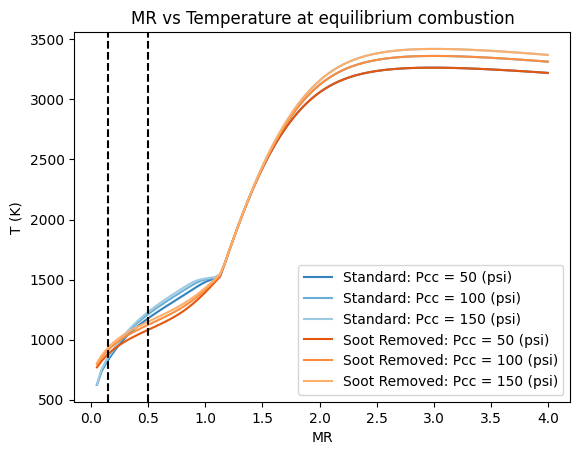

In [11]:
# T comparison
colors = plt.get_cmap('tab20c').colors   # tuple of 20 RGB colors
colors = plt.get_cmap('tab20c').colors
for i in range(len(chamberPs)):
    plt.plot(MRRange, Ts[i, :], label=f"Standard: Pcc = {chamberPs[i]} (psi)", color=colors[i])
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootTs[i, :],     label=f"Soot Removed: Pcc = {chamberPs[i]} (psi)",     color=colors[i + 4])
plt.title("MR vs Temperature at equilibrium combustion")
plt.xlabel("MR")
plt.ylabel("T (K)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

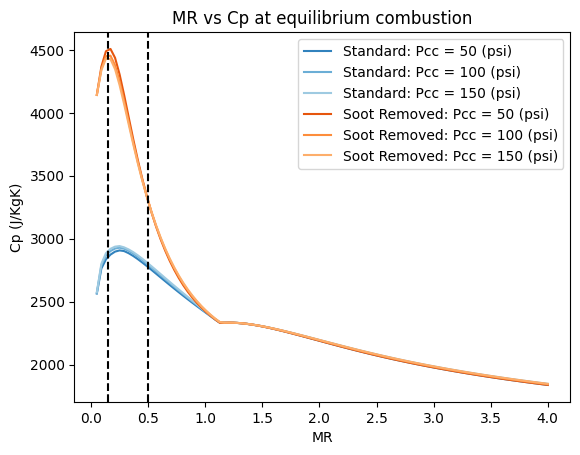

In [12]:
# Cp comparison
colors = plt.get_cmap('tab20c').colors   # tuple of 20 RGB colors
colors = plt.get_cmap('tab20c').colors
for i in range(len(chamberPs)):
    plt.plot(MRRange, Cps[i, :], label=f"Standard: Pcc = {chamberPs[i]} (psi)", color=colors[i])
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootCps[i, :],     label=f"Soot Removed: Pcc = {chamberPs[i]} (psi)",     color=colors[i + 4])
plt.title("MR vs Cp at equilibrium combustion")
plt.xlabel("MR")
plt.ylabel("Cp (J/KgK)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')